## 04 . Customer Segmentation RFM(Recency, Frequency, Monetary)

In [1]:
## Import liberaries 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [3]:
# 1. Load Data

PROCESSED_PATH = "../data/processed/"

orders = pd.read_csv(PROCESSED_PATH + "orders_clean.csv")
customers = pd.read_csv(PROCESSED_PATH + "customers_clean.csv")

orders['order_date'] = pd.to_datetime(orders['order_date'])

print("Data loaded successfully!")

Data loaded successfully!


In [4]:
# 2. Calculate RFM Metrics

print("\nCalculating RFM Metrics...")

### Reference date (latest order date + 1 day)

reference_date = orders['order_date'].max() + pd.Timedelta(days=1)

### Calculate Recency, Frequency, Monetary
rfm= orders.groupby('customer_id').agg({
    'order_date' : lambda x: (reference_date - x.max()).days,       ## Recency
    'order_id' : 'nunique',                                         ## Frequency
    'final_amount' : 'sum'                                          ## Monetary
}).reset_index()


rfm.columns = ['customer_id','recency' ,'frequency', 'monetary']

print(rfm.head())


Calculating RFM Metrics...
  customer_id  recency  frequency   monetary
0  CUST100000      951          3   36884.57
1  CUST100001      588          7  371585.73
2  CUST100002      171         10  114901.74
3  CUST100003       13          1    3788.82
4  CUST100004      792          2   61295.90


In [7]:
# 3. Create RFM Scores (1-5)

### Lower recency is better → reverse scoring

rfm['R_score'] = pd.qcut(rfm['recency'], 5, labels=[5,4,3,2,1])
rfm['F_score'] = pd.qcut(rfm['frequency'].rank(method='first'), 5, labels=[1,2,3,4,5])
rfm['M_score'] = pd.qcut(rfm['monetary'], 5 , labels= [1,2,3,4,5])

### Covert to integer

rfm['R_score'] = rfm['R_score'].astype(int)
rfm['F_score'] = rfm['F_score'].astype(int)
rfm['M_score'] = rfm['F_score'].astype(int)

### Combined RFM score

rfm['RFM_score'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str) + rfm['M_score'].astype(str)

print("\nRFM Scores created!")
print(rfm.head())


RFM Scores created!
  customer_id  recency  frequency   monetary  R_score  F_score  M_score  \
0  CUST100000      951          3   36884.57        1        2        2   
1  CUST100001      588          7  371585.73        2        4        4   
2  CUST100002      171         10  114901.74        3        5        5   
3  CUST100003       13          1    3788.82        5        1        1   
4  CUST100004      792          2   61295.90        1        1        1   

  RFM_score  
0       122  
1       244  
2       355  
3       511  
4       111  


In [9]:
# 4. Customer Segmentation

def segment_customer(row):
    if row['R_score'] >=4 and row['F_score'] >=4 and row['M_score'] >=4:
        return 'Champions'
    elif row['R_score'] >= 3 and row['F_score'] >= 3 and row['M_score'] >= 3:
        return 'Loyal Customers'
    elif row['R_score'] >= 4 and row['F_score'] <= 2:
        return 'Promising'
    elif row['R_score'] >= 3 and row['F_score'] <= 2:
        return 'Need Attention'
    elif row['R_score'] <= 2 and row['F_score'] >= 3:
        return 'At Risk'
    elif row['R_score'] <= 2 and row['F_score'] <= 2 and row['M_score'] <= 2:
        return 'Lost'
    else:
        return 'Others'
    
rfm['Segment'] = rfm.apply(segment_customer,axis=1)

print("\nCustomer Segments:")
print(rfm['Segment'].value_counts())


Customer Segments:
Segment
At Risk            4945
Loyal Customers    4485
Champions          4262
Lost               4163
Promising          2967
Need Attention     1998
Name: count, dtype: int64


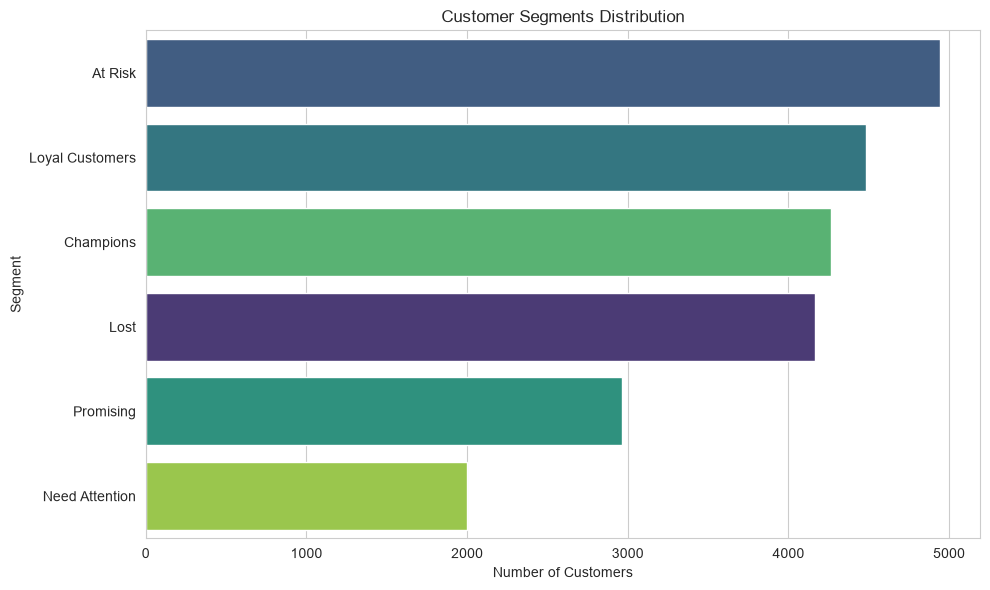

In [15]:
# 5. Visualization

plt.figure(figsize=(10, 6))
sns.countplot(data=rfm, y='Segment', order=rfm['Segment'].value_counts().index, palette='viridis',hue=rfm['Segment'] )
plt.title("Customer Segments Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Segment")
plt.tight_layout()
plt.show()

In [17]:
# Save RFM Results

rfm.to_csv(PROCESSED_PATH + "rfm_segments.csv", index=False)
print("\nRFM segments saved to data/processed/rfm_segments.csv")


RFM segments saved to data/processed/rfm_segments.csv


RFM Segments Created:

- Champions
- Loyal Customers
- Promising
- Need Attention
- At Risk
- Lost
- Others